# KNN 알고리즘 실습

In [14]:
# 데이터 전처리 (문제 정의, 데이터 수집, 데이터 전처리 (시각화), 데이터 전처리 (다듬기), 데이터 분류 (나누기), 데이터 보관)
# 라이브러리 임포트 : 실습에 필요한 라이브러리를 임포트
import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt
import seaborn           as sns

from sklearn import set_config
set_config(display="text")

import warnings # 경고 메시지 무시
warnings.filterwarnings("ignore")

# sklearn 모델의 동일한 결과 출력을 위해 선언
np.random.seed(1234)

# 데이터 불러오기(학습데이터, 테스트 데이터)

#### - 데이터 분석 단계에서 생성한 농구 선수 포지션 예측하기의 학습 데이터 및 테스트 데이터를 읽어오기

In [15]:
train = pd.read_csv("./data/csv/basketball_train.csv")
test  = pd.read_csv("./data/csv/basketball_test.csv")

print("훈련용 => 행 : {}, 열 :{} " "\n" "\n"
      "테스트 => 행 : {}, 열 :{} " "\n".format(train.shape[0]
                                            , train.shape[1]
                                            , test.shape[0]
                                            , test.shape[1])) # 데이터 셋 갯수
train



훈련용 => 행 : 80, 열 :5 

테스트 => 행 : 20, 열 :5 



,Player,Pos,3P,TRB,BLK
0,Dewayne Dedmon,C,0.0,6.5,0.8
1,Manu Ginobili,SG,1.3,2.3,0.2
2,Salah Mejri,C,0.0,4.2,0.8
3,Nene Hilario,C,0.0,4.2,0.6
4,Jordan Crawford,SG,1.9,1.8,0.1
...,...,...,...,...,...
75,Wayne Ellington,SG,2.4,2.1,0.1
76,Wesley Matthews,SG,2.4,3.5,0.2
77,Patrick Beverley,SG,1.6,5.9,0.4
78,Marcus Smart,SG,1.2,3.9,0.4


# 최적의 k 찾기(교차 검증 cross validation)

In [16]:
from sklearn.neighbors import  KNeighborsClassifier # 클래스
from sklearn.model_selection import cross_val_score # 함수

In [17]:
# 최적의 k값 찾기
max_k_range = train.shape[0] // 2 # 몪만 챙김 전체 데이터 절반 정도 데이터를 검증
k_list = []

for i in range(3, max_k_range, 2):
  k_list.append(i)

x_train = train[['3P','BLK', 'TRB']]
y_train = train[['Pos']]

print(x_train.shape) # 훈련
print(y_train.shape)
print(x_train)
print(y_train)

(80, 3)
(80, 1)
     3P  BLK  TRB
0   0.0  0.8  6.5
1   1.3  0.2  2.3
2   0.0  0.8  4.2
3   0.0  0.6  4.2
4   1.9  0.1  1.8
..  ...  ...  ...
75  2.4  0.1  2.1
76  2.4  0.2  3.5
77  1.6  0.4  5.9
78  1.2  0.4  3.9
79  1.7  0.3  2.9

[80 rows x 3 columns]
   Pos
0    C
1   SG
2    C
3    C
4   SG
..  ..
75  SG
76  SG
77  SG
78  SG
79  SG

[80 rows x 1 columns]


In [18]:
print(y_train.values.ravel()) # 개별 데이터

['C' 'SG' 'C' 'C' 'SG' 'SG' 'C' 'C' 'C' 'SG' 'C' 'SG' 'SG' 'C' 'C' 'C'
 'SG' 'C' 'C' 'SG' 'C' 'C' 'SG' 'C' 'C' 'C' 'C' 'SG' 'C' 'SG' 'C' 'C' 'SG'
 'C' 'SG' 'SG' 'SG' 'C' 'SG' 'C' 'SG' 'C' 'C' 'C' 'SG' 'SG' 'SG' 'SG' 'C'
 'C' 'SG' 'SG' 'C' 'C' 'SG' 'SG' 'C' 'C' 'SG' 'C' 'C' 'SG' 'C' 'C' 'SG'
 'C' 'C' 'C' 'C' 'SG' 'SG' 'C' 'C' 'SG' 'SG' 'SG' 'SG' 'SG' 'SG' 'SG']


In [19]:
# k-fold cross validation(k-폴드 교차 검증법) = 훈련용 80 ->  크로스 하면서 검증용 20씩 검증 몇번 반복 학습
cross_validation_score = []

for k in k_list: #3,5,..., 39
  knn = KNeighborsClassifier(n_neighbors=k)
  scores = cross_val_score(knn, x_train, y_train.values.ravel(), cv=10, scoring ='accuracy')
  cross_validation_score.append(scores.mean())

cross_validation_score

[np.float64(0.95),
 np.float64(0.9125),
 np.float64(0.9125),
 np.float64(0.9),
 np.float64(0.8875),
 np.float64(0.8875),
 np.float64(0.8875),
 np.float64(0.9),
 np.float64(0.875),
 np.float64(0.8875),
 np.float64(0.8625),
 np.float64(0.8625),
 np.float64(0.8625),
 np.float64(0.8625),
 np.float64(0.8375),
 np.float64(0.8375),
 np.float64(0.825),
 np.float64(0.825),
 np.float64(0.825)]

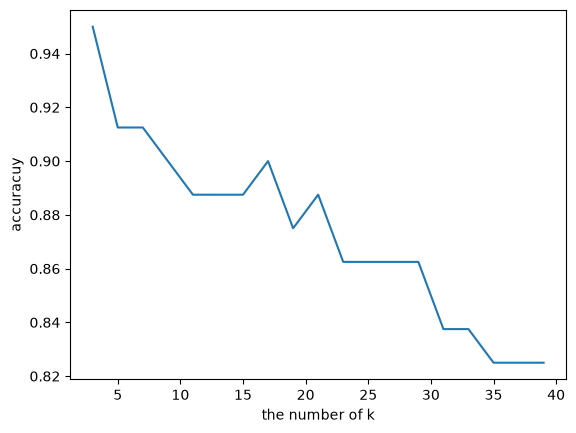

In [20]:
# k값 시각화

plt.plot(k_list, cross_validation_score)
plt.xlabel("the number of k")
plt.ylabel("accuracuy")
plt.show()

In [21]:
cvs = cross_validation_score

k = k_list[cvs.index(max(cross_validation_score))]

str(k)

'3'

# - 2개의 특징으로 예측하기(3점슛, 블로킹)

In [22]:
knn = KNeighborsClassifier(n_neighbors=k) # 모델 생성

x_train = train[['3P', 'BLK']]
y_train = train[['Pos']]

knn.fit(x_train, y_train.values.ravel()) # raval 2차원배열을 -> 1차원배열으로 변환

KNeighborsClassifier(n_neighbors=3)

In [23]:
# knn 정확도
x_test = test[['3P', 'BLK']]
y_test = test[['Pos']]

pred = knn.predict(x_test) # 예측값


In [24]:
comparsion = pd.DataFrame({'예측값' : pred, '정답' : y_test.values.ravel()})
comparsion

,예측값,정답
0,SG,SG
1,SG,SG
2,SG,SG
3,SG,SG
4,SG,SG
5,SG,C
6,SG,SG
7,SG,C
8,C,C
9,SG,SG


In [25]:
# 정확도
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print('accuracy : ', str(accuracy_score(pred, y_test.values.ravel())))

accuracy :  0.9


In [26]:
knn = KNeighborsClassifier(n_neighbors=k) # 모델 생성

x_train = train[['3P', 'BLK', 'TRB']]
y_train = train[['Pos']]

knn.fit(x_train, y_train.values.ravel()) # raval 2차원배열을 -> 1차원배열으로 변환

KNeighborsClassifier(n_neighbors=3)

In [27]:
# knn 정확도
x_test = test[['3P', 'BLK', 'TRB']]
y_test = test[['Pos']]

pred = knn.predict(x_test)

# check ground_truth with knn prediction
comparison = pd.DataFrame(
    {'prediction':pred, 'ground_truth':y_test.values.ravel()}) 
comparison

,prediction,ground_truth
0,SG,SG
1,SG,SG
2,SG,SG
3,SG,SG
4,SG,SG
5,SG,C
6,SG,SG
7,SG,C
8,C,C
9,SG,SG


In [28]:
# 정확도
print("accuracy : " , str(accuracy_score(y_test.values.ravel(), pred)) )

accuracy :  0.9
